In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 0. STYLE CONFIGURATION ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 20,
        "axes.labelsize" : 20,
        "legend.fontsize" : 14,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 18,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 18,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)


--> Loading fiducial_452Halos_FullSpectra_new.pkl...
--> Loading LH_0_452Halos_FullSpectra.pkl...
--> Filtering halos with mass between 11.0 and 11.4 log10(M_sun)

--- Halos Count per Radius Bin (Mass Filtered) ---
Radius 1 (R_mult = 0.10): Fiducial = 142 halos | LH_0 = 151 halos
Radius 2 (R_mult = 0.23): Fiducial = 142 halos | LH_0 = 151 halos
Radius 3 (R_mult = 0.55): Fiducial = 142 halos | LH_0 = 151 halos
Radius 4 (R_mult = 1.28): Fiducial = 142 halos | LH_0 = 151 halos
Radius 5 (R_mult = 3.00): Fiducial = 142 halos | LH_0 = 151 halos
------------------------------------------

--> Figure saved to: Comparison_Fiducial_vs_LH0_MassBin_11.0_11.4.pdf


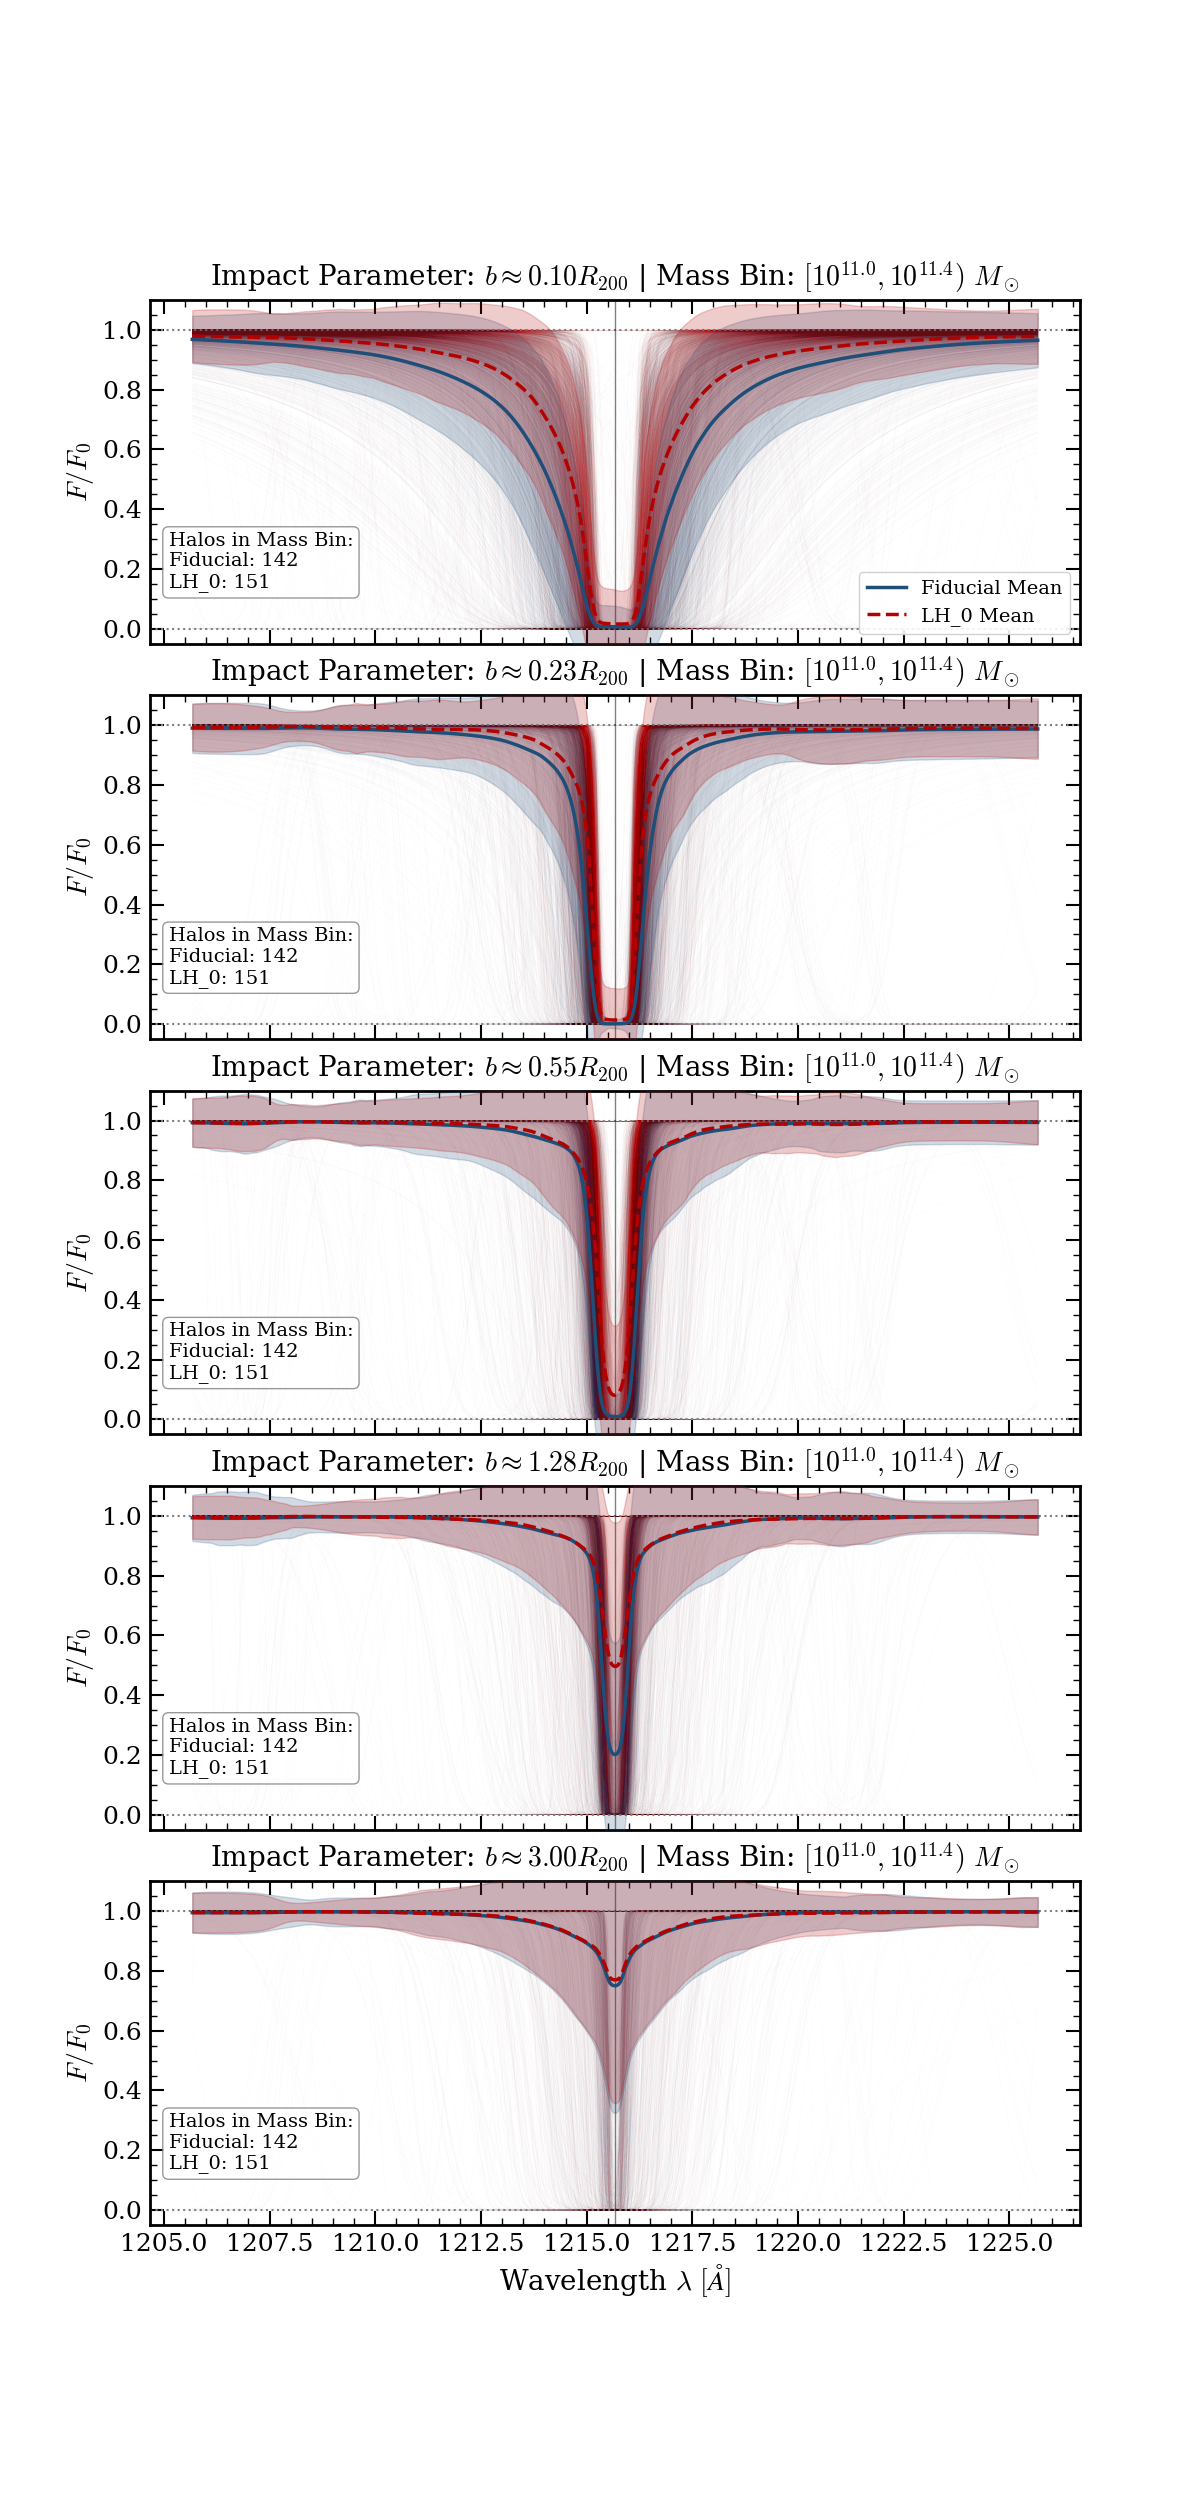

In [ ]:
# --- 1. PARAMETERS ---
PKL_FIDUCIAL = "fiducial_452Halos_FullSpectra_new.pkl"
PKL_LH0 = "LH_0_452Halos_FullSpectra.pkl"
H_HUBBLE = 0.6774 

# Define the target mass bin (log10 Msun)
TARGET_MASS_MIN = 11.0
TARGET_MASS_MAX = 11.4

# Base colors for the comparison (Blue for Fiducial, Red for LH_0)
COLOR_FID = '#1f4e78' # Strong Blue
COLOR_LH0 = '#b30000' # Strong Red

# --- 2. DATA LOADING & PREP ---
if not os.path.exists(PKL_FIDUCIAL) or not os.path.exists(PKL_LH0):
    print("ERROR: One of the .pkl files was not found. Check your directory.")
    import sys; sys.exit()

print(f"--> Loading {PKL_FIDUCIAL}...")
df_fid = pd.read_pickle(PKL_FIDUCIAL)

print(f"--> Loading {PKL_LH0}...")
df_lh0 = pd.read_pickle(PKL_LH0)

# Calculate log_mass_msun
df_fid['log_mass_msun'] = np.log10((df_fid['halo_mass'] * 1e10) / H_HUBBLE)
df_lh0['log_mass_msun'] = np.log10((df_lh0['halo_mass'] * 1e10) / H_HUBBLE)

# Filter DataFrames for the target mass bin ONLY
print(f"--> Filtering halos with mass between {TARGET_MASS_MIN} and {TARGET_MASS_MAX} log10(M_sun)")
mask_mass_fid = (df_fid['log_mass_msun'] >= TARGET_MASS_MIN) & (df_fid['log_mass_msun'] < TARGET_MASS_MAX)
mask_mass_lh0 = (df_lh0['log_mass_msun'] >= TARGET_MASS_MIN) & (df_lh0['log_mass_msun'] < TARGET_MASS_MAX)

df_fid_mass_bin = df_fid[mask_mass_fid]
df_lh0_mass_bin = df_lh0[mask_mass_lh0]

# Identify the 5 Radius Bins (Impact Parameters)
available_radii = np.sort(df_fid['r_multiplier'].unique())
NUM_RADII = len(available_radii)

print("\n--- Halos Count per Radius Bin (Mass Filtered) ---")

# --- 3. PLOTTING ---
# Create 5 panels, one for each impact radius
fig, axes = plt.subplots(NUM_RADII, 1, figsize=(12, 5 * NUM_RADII), sharex=True)

# Common interpolation grid (Wide enough to see the absorption wings)
wave_grid = np.linspace(1215.67 - 10, 1215.67 + 10, 600)

for ax_idx, r_target in enumerate(available_radii):
    ax = axes[ax_idx]
    
    # Filter DataFrames for the current radius bin
    bin_fid = df_fid_mass_bin[df_fid_mass_bin['r_multiplier'] == r_target]
    bin_lh0 = df_lh0_mass_bin[df_lh0_mass_bin['r_multiplier'] == r_target]
    
    # Count unique halos in this specific mass + radius bin
    num_halos_fid = bin_fid['halo_id'].nunique()
    num_halos_lh0 = bin_lh0['halo_id'].nunique()
    
    # Print the counts to the terminal
    print(f"Radius {ax_idx+1} (R_mult = {r_target:.2f}): Fiducial = {num_halos_fid} halos | LH_0 = {num_halos_lh0} halos")
    
    # Set subplot title explicitly mentioning the mass bin
    title_str = f"Impact Parameter: $b \\approx {r_target:.2f} R_{{200}}$ | Mass Bin: $[10^{{{TARGET_MASS_MIN}}}, 10^{{{TARGET_MASS_MAX}}}) \\ M_\\odot$"
    ax.set_title(title_str, pad=10)

    # ================= FIDUCIAL (Blue) =================
    if not bin_fid.empty:
        # Interpolate all spectra to the common grid
        flux_mat_fid = np.array([np.interp(wave_grid, row['wave'], row['flux']) for _, row in bin_fid.iterrows()])
        
        # Calculate Statistics
        mean_fid = np.nanmean(flux_mat_fid, axis=0)
        std_fid = np.nanstd(flux_mat_fid, axis=0)
        
        # Plot Individual Thin Lines (alpha very low to not clutter)
        for f in flux_mat_fid:
            ax.plot(wave_grid, f, color=COLOR_FID, alpha=0.015, lw=0.5, zorder=1, rasterized=True)
            
        # Plot Mean and Std
        lbl_fid = "Fiducial Mean" if ax_idx == 0 else None
        ax.plot(wave_grid, mean_fid, color=COLOR_FID, lw=2.5, label=lbl_fid, zorder=10)
        ax.fill_between(wave_grid, mean_fid - std_fid, mean_fid + std_fid, color=COLOR_FID, alpha=0.2, zorder=5)

    # ================= LH_0 (Red) =================
    if not bin_lh0.empty:
        # Interpolate all spectra to the common grid
        flux_mat_lh0 = np.array([np.interp(wave_grid, row['wave'], row['flux']) for _, row in bin_lh0.iterrows()])
        
        # Calculate Statistics
        mean_lh0 = np.nanmean(flux_mat_lh0, axis=0)
        std_lh0 = np.nanstd(flux_mat_lh0, axis=0)
        
        # Plot Individual Thin Lines
        for f in flux_mat_lh0:
            ax.plot(wave_grid, f, color=COLOR_LH0, alpha=0.015, lw=0.5, zorder=1, rasterized=True)
            
        # Plot Mean and Std (using dashed line to differentiate easily)
        lbl_lh0 = "LH_0 Mean" if ax_idx == 0 else None
        ax.plot(wave_grid, mean_lh0, color=COLOR_LH0, lw=2.5, linestyle='--', label=lbl_lh0, zorder=11)
        ax.fill_between(wave_grid, mean_lh0 - std_lh0, mean_lh0 + std_lh0, color=COLOR_LH0, alpha=0.2, zorder=6)

    # --- ADD HALO COUNT TEXT BOX TO PLOT ---
    text_str = f"Halos in Mass Bin:\nFiducial: {num_halos_fid}\nLH_0: {num_halos_lh0}"
    props = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
    ax.text(0.02, 0.15, text_str, transform=ax.transAxes, fontsize=14,
            verticalalignment='bottom', bbox=props, zorder=20)

    # --- REFERENCE LINES & LIMITS ---
    ax.axhline(1.0, color='gray', linestyle=':', lw=1.5)
    ax.axhline(0.0, color='gray', linestyle=':', lw=1.5)
    ax.axvline(1215.67, color='black', linestyle='-', lw=1.0, alpha=0.5)

    ax.set_ylim(-0.05, 1.1)
    ax.set_ylabel(r'$F/F_0$')
    
    # Legend only on the first panel
    if ax_idx == 0:
        ax.legend(loc='lower right', framealpha=0.9, fontsize=14)

print("------------------------------------------\n")

# Format the X-axis only on the bottom panel
axes[-1].set_xlabel(r'Wavelength $\lambda\ [\AA]$')
fig.subplots_adjust(hspace=0.15)

# Save the Figure
output_img = f"Comparison_Fiducial_vs_LH0_MassBin_{TARGET_MASS_MIN}_{TARGET_MASS_MAX}.pdf"
#plt.savefig(output_img, bbox_inches='tight', dpi=300)
#print(f"--> Figure saved to: {output_img}")

plt.show()

## Multiple Re-sims comparisson

--> Loading fiducial_452Halos_FullSpectra_new.pkl...
--> Loading LH_0_452Halos_FullSpectra.pkl...


--> Loading LH_1_452Halos_FullSpectra.pkl...
--> Filtering halos with mass between 11.0 and 11.4 log10(M_sun)

--- Halos Count per Radius Bin (Mass Filtered) ---
Radius 1 (R_mult = 0.10): Fiducial = 142 | LH_0 = 151 | LH_1 = 147
Radius 2 (R_mult = 0.23): Fiducial = 142 | LH_0 = 151 | LH_1 = 147
Radius 3 (R_mult = 0.55): Fiducial = 142 | LH_0 = 151 | LH_1 = 147
Radius 4 (R_mult = 1.28): Fiducial = 142 | LH_0 = 151 | LH_1 = 147
Radius 5 (R_mult = 3.00): Fiducial = 142 | LH_0 = 151 | LH_1 = 147
------------------------------------------

--> Figure saved to: Comparison_Fiducial_LH0_LH1_MassBin_11.0_11.4.pdf


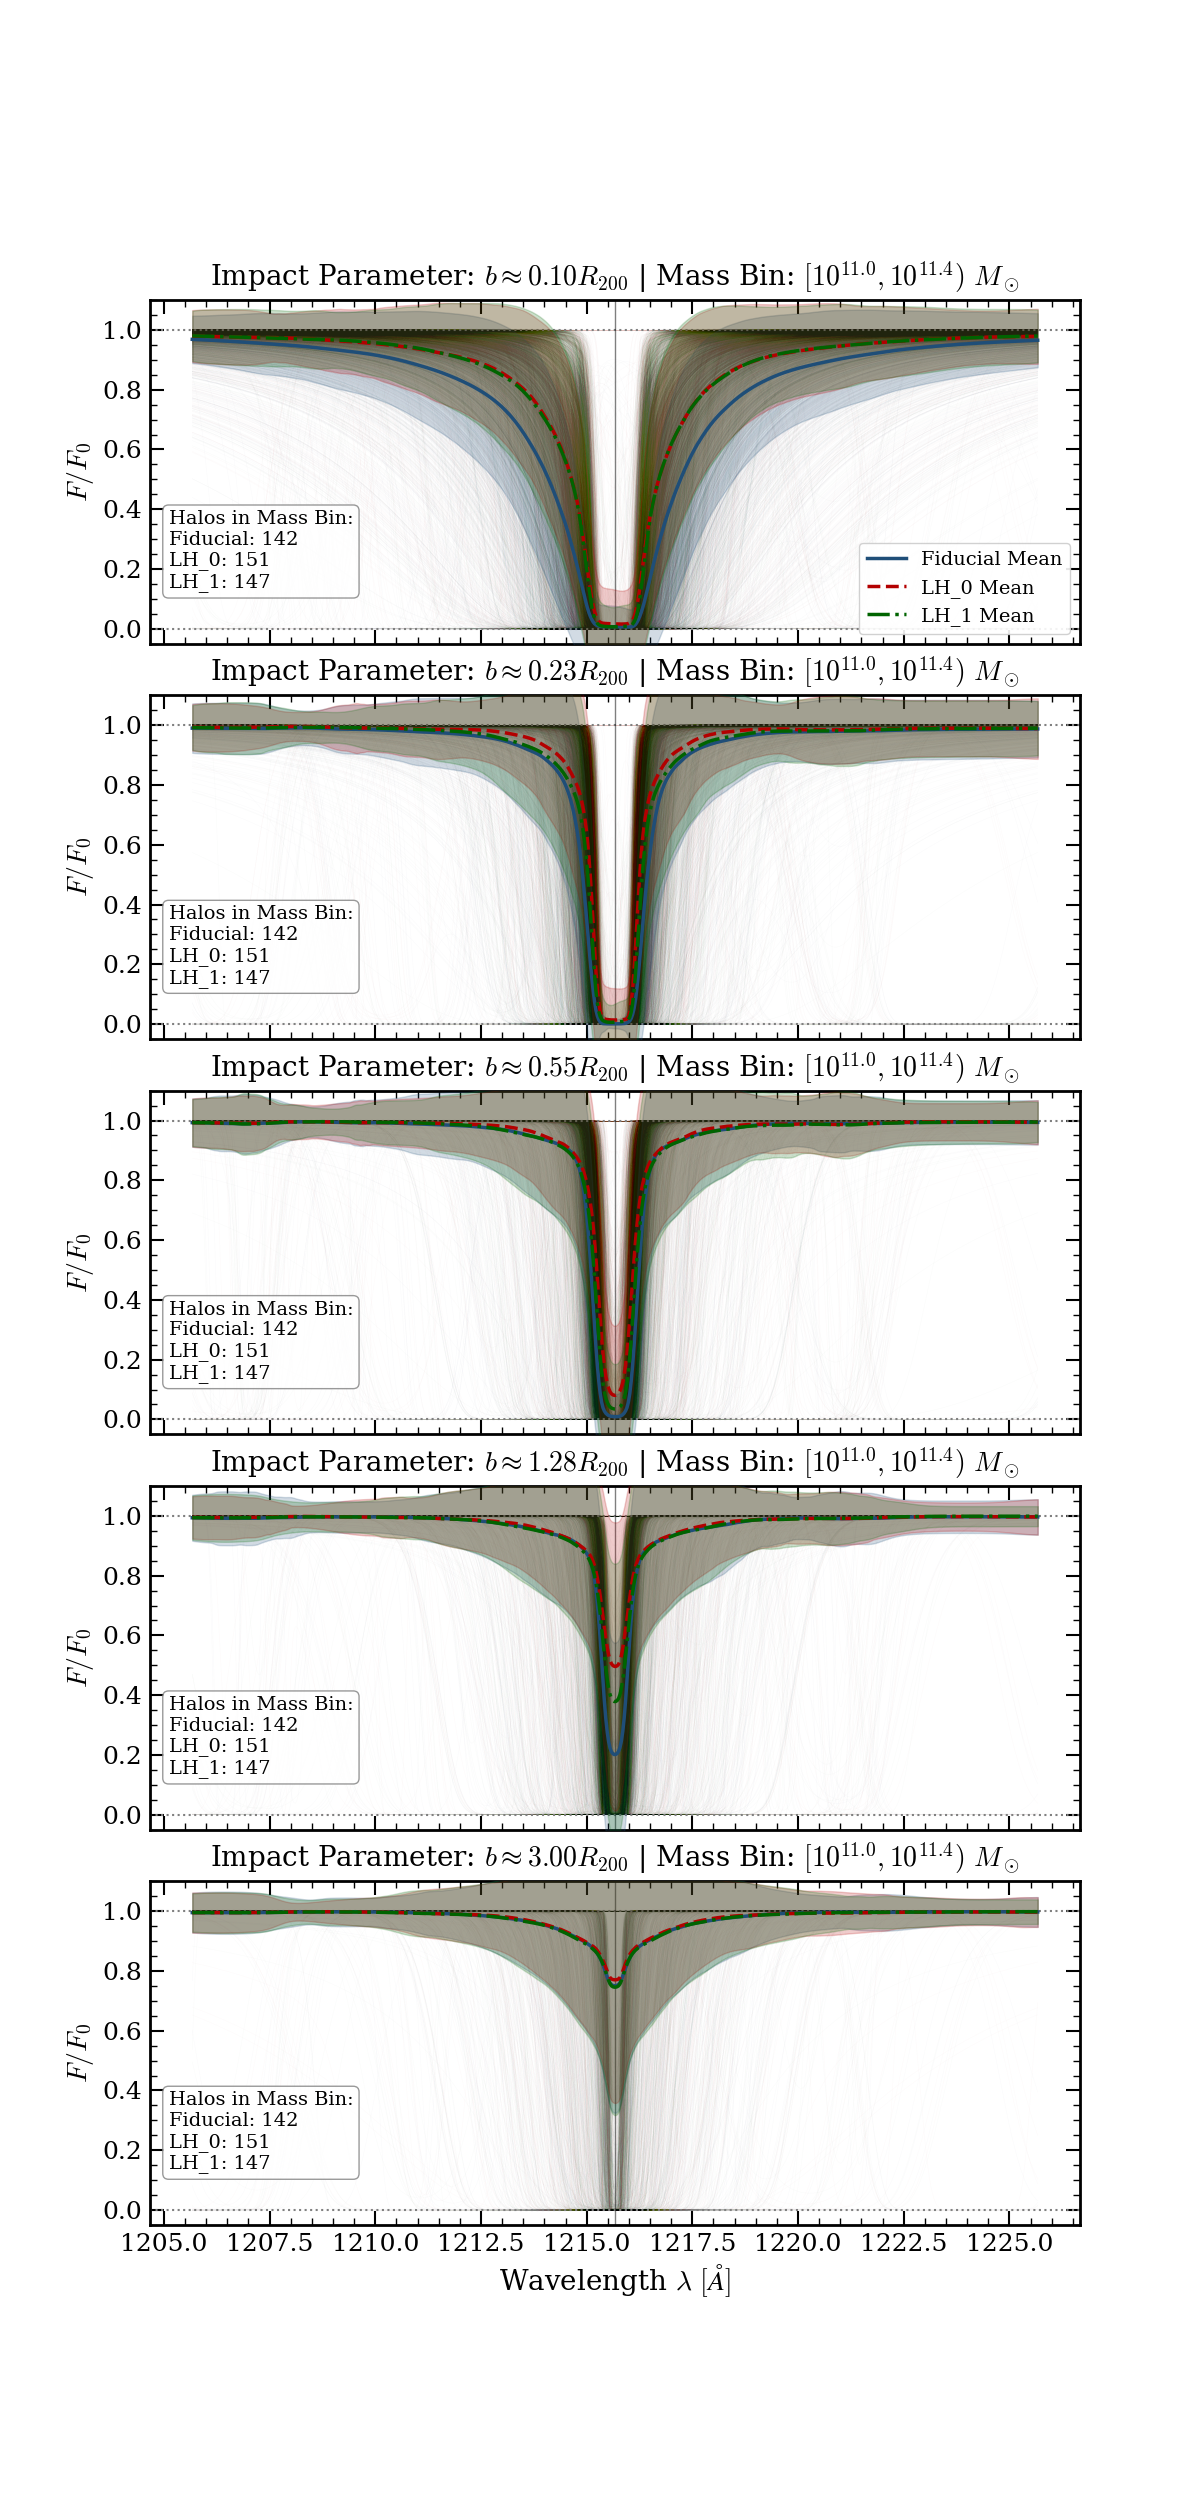

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 0. STYLE CONFIGURATION ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 20,
        "axes.labelsize" : 20,
        "legend.fontsize" : 14,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 18,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 18,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew
    

# Apply Config
%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# --- 1. PARAMETERS ---
PKL_FIDUCIAL = "fiducial_452Halos_FullSpectra_new.pkl"
PKL_LH0 = "LH_0_452Halos_FullSpectra.pkl"
PKL_LH1 = "LH_1_452Halos_FullSpectra.pkl"
H_HUBBLE = 0.6774 

# Define the target mass bin (log10 Msun)
TARGET_MASS_MIN = 11.0
TARGET_MASS_MAX = 11.4

# Base colors for the comparison (Blue for Fiducial, Red for LH_0, Green for LH_1)
COLOR_FID = '#1f4e78' # Strong Blue
COLOR_LH0 = '#b30000' # Strong Red
COLOR_LH1 = '#006400' # Dark Green

# --- 2. DATA LOADING & PREP ---
if not os.path.exists(PKL_FIDUCIAL) or not os.path.exists(PKL_LH0) or not os.path.exists(PKL_LH1):
    print("ERROR: One of the .pkl files was not found. Check your directory.")
    import sys; sys.exit()

print(f"--> Loading {PKL_FIDUCIAL}...")
df_fid = pd.read_pickle(PKL_FIDUCIAL)

print(f"--> Loading {PKL_LH0}...")
df_lh0 = pd.read_pickle(PKL_LH0)

print(f"--> Loading {PKL_LH1}...")
df_lh1 = pd.read_pickle(PKL_LH1)

# Calculate log_mass_msun
df_fid['log_mass_msun'] = np.log10((df_fid['halo_mass'] * 1e10) / H_HUBBLE)
df_lh0['log_mass_msun'] = np.log10((df_lh0['halo_mass'] * 1e10) / H_HUBBLE)
df_lh1['log_mass_msun'] = np.log10((df_lh1['halo_mass'] * 1e10) / H_HUBBLE)

# Filter DataFrames for the target mass bin ONLY
print(f"--> Filtering halos with mass between {TARGET_MASS_MIN} and {TARGET_MASS_MAX} log10(M_sun)")
mask_mass_fid = (df_fid['log_mass_msun'] >= TARGET_MASS_MIN) & (df_fid['log_mass_msun'] < TARGET_MASS_MAX)
mask_mass_lh0 = (df_lh0['log_mass_msun'] >= TARGET_MASS_MIN) & (df_lh0['log_mass_msun'] < TARGET_MASS_MAX)
mask_mass_lh1 = (df_lh1['log_mass_msun'] >= TARGET_MASS_MIN) & (df_lh1['log_mass_msun'] < TARGET_MASS_MAX)

df_fid_mass_bin = df_fid[mask_mass_fid]
df_lh0_mass_bin = df_lh0[mask_mass_lh0]
df_lh1_mass_bin = df_lh1[mask_mass_lh1]

# Identify the 5 Radius Bins (Impact Parameters)
available_radii = np.sort(df_fid['r_multiplier'].unique())
NUM_RADII = len(available_radii)

print("\n--- Halos Count per Radius Bin (Mass Filtered) ---")

# --- 3. PLOTTING ---
# Create 5 panels, one for each impact radius
fig, axes = plt.subplots(NUM_RADII, 1, figsize=(12, 5 * NUM_RADII), sharex=True)

# Common interpolation grid (Wide enough to see the absorption wings)
wave_grid = np.linspace(1215.67 - 10, 1215.67 + 10, 600)

for ax_idx, r_target in enumerate(available_radii):
    ax = axes[ax_idx]
    
    # Filter DataFrames for the current radius bin
    bin_fid = df_fid_mass_bin[df_fid_mass_bin['r_multiplier'] == r_target]
    bin_lh0 = df_lh0_mass_bin[df_lh0_mass_bin['r_multiplier'] == r_target]
    bin_lh1 = df_lh1_mass_bin[df_lh1_mass_bin['r_multiplier'] == r_target]
    
    # Count unique halos in this specific mass + radius bin
    num_halos_fid = bin_fid['halo_id'].nunique()
    num_halos_lh0 = bin_lh0['halo_id'].nunique()
    num_halos_lh1 = bin_lh1['halo_id'].nunique()
    
    # Print the counts to the terminal
    print(f"Radius {ax_idx+1} (R_mult = {r_target:.2f}): Fiducial = {num_halos_fid} | LH_0 = {num_halos_lh0} | LH_1 = {num_halos_lh1}")
    
    # Set subplot title explicitly mentioning the mass bin
    title_str = f"Impact Parameter: $b \\approx {r_target:.2f} R_{{200}}$ | Mass Bin: $[10^{{{TARGET_MASS_MIN}}}, 10^{{{TARGET_MASS_MAX}}}) \\ M_\\odot$"
    ax.set_title(title_str, pad=10)

    # ================= FIDUCIAL (Blue, Solid Line) =================
    if not bin_fid.empty:
        flux_mat_fid = np.array([np.interp(wave_grid, row['wave'], row['flux']) for _, row in bin_fid.iterrows()])
        mean_fid = np.nanmean(flux_mat_fid, axis=0)
        std_fid = np.nanstd(flux_mat_fid, axis=0)
        
        for f in flux_mat_fid:
            ax.plot(wave_grid, f, color=COLOR_FID, alpha=0.015, lw=0.5, zorder=1, rasterized=True)
            
        lbl_fid = "Fiducial Mean" if ax_idx == 0 else None
        ax.plot(wave_grid, mean_fid, color=COLOR_FID, lw=2.5, linestyle='-', label=lbl_fid, zorder=10)
        ax.fill_between(wave_grid, mean_fid - std_fid, mean_fid + std_fid, color=COLOR_FID, alpha=0.2, zorder=5)

    # ================= LH_0 (Red, Dashed Line) =================
    if not bin_lh0.empty:
        flux_mat_lh0 = np.array([np.interp(wave_grid, row['wave'], row['flux']) for _, row in bin_lh0.iterrows()])
        mean_lh0 = np.nanmean(flux_mat_lh0, axis=0)
        std_lh0 = np.nanstd(flux_mat_lh0, axis=0)
        
        for f in flux_mat_lh0:
            ax.plot(wave_grid, f, color=COLOR_LH0, alpha=0.015, lw=0.5, zorder=1, rasterized=True)
            
        lbl_lh0 = "LH_0 Mean" if ax_idx == 0 else None
        ax.plot(wave_grid, mean_lh0, color=COLOR_LH0, lw=2.5, linestyle='--', label=lbl_lh0, zorder=11)
        ax.fill_between(wave_grid, mean_lh0 - std_lh0, mean_lh0 + std_lh0, color=COLOR_LH0, alpha=0.2, zorder=6)

    # ================= LH_1 (Green, Dash-Dot Line) =================
    if not bin_lh1.empty:
        flux_mat_lh1 = np.array([np.interp(wave_grid, row['wave'], row['flux']) for _, row in bin_lh1.iterrows()])
        mean_lh1 = np.nanmean(flux_mat_lh1, axis=0)
        std_lh1 = np.nanstd(flux_mat_lh1, axis=0)
        
        for f in flux_mat_lh1:
            ax.plot(wave_grid, f, color=COLOR_LH1, alpha=0.015, lw=0.5, zorder=1, rasterized=True)
            
        lbl_lh1 = "LH_1 Mean" if ax_idx == 0 else None
        # Using dash-dot ('-.') to clearly distinguish from the solid and dashed lines
        ax.plot(wave_grid, mean_lh1, color=COLOR_LH1, lw=2.5, linestyle='-.', label=lbl_lh1, zorder=12)
        ax.fill_between(wave_grid, mean_lh1 - std_lh1, mean_lh1 + std_lh1, color=COLOR_LH1, alpha=0.2, zorder=7)

    # --- ADD HALO COUNT TEXT BOX TO PLOT ---
    text_str = f"Halos in Mass Bin:\nFiducial: {num_halos_fid}\nLH_0: {num_halos_lh0}\nLH_1: {num_halos_lh1}"
    props = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
    ax.text(0.02, 0.15, text_str, transform=ax.transAxes, fontsize=14,
            verticalalignment='bottom', bbox=props, zorder=20)

    # --- REFERENCE LINES & LIMITS ---
    ax.axhline(1.0, color='gray', linestyle=':', lw=1.5)
    ax.axhline(0.0, color='gray', linestyle=':', lw=1.5)
    ax.axvline(1215.67, color='black', linestyle='-', lw=1.0, alpha=0.5)

    ax.set_ylim(-0.05, 1.1)
    ax.set_ylabel(r'$F/F_0$')
    
    # Legend only on the first panel
    if ax_idx == 0:
        ax.legend(loc='lower right', framealpha=0.9, fontsize=14)

print("------------------------------------------\n")

# Format the X-axis only on the bottom panel
axes[-1].set_xlabel(r'Wavelength $\lambda\ [\AA]$')
fig.subplots_adjust(hspace=0.15)

# Save the Figure
output_img = f"Comparison_Fiducial_LH0_LH1_MassBin_{TARGET_MASS_MIN}_{TARGET_MASS_MAX}.pdf"
plt.savefig(output_img, bbox_inches='tight', dpi=300)
print(f"--> Figure saved to: {output_img}")

plt.show()